# Phase 2 (Walk): Time-Series Volatility Regimes, EGARCH(1,1) FHS & Dynamic Historical Simulation
**Multi-Asset Macro Trading Desk ($10,000,000 Notional | CRO 1-Day 99% VaR Cap = $200,000)**

### Executive Objective
Equally weighted rolling windows suffer from **slow crisis reaction** and **250-day "ghost effects"**. This notebook upgrades the risk engine using conditional time-series volatility models:
1. **Diagnosing the 250-Day "Ghost Effect":** Tracking 250-day Plain Historical Simulation VaR across 2020–2021.
2. **RiskMetrics EWMA Volatility ($\lambda = 0.94$)** & **Bollerslev $\text{GARCH}(1,1)$ (Normal & Student-$t$)**.
3. **Asymmetric $\text{EGARCH}(1,1)$ Filtered Historical Simulation (FHS) (Nelson, 1991):** Drawing directly on asymmetric log-variance specification $\ln(\sigma_t^2) = \omega + \alpha_1(|z_{t-1}| - \mathbb{E}|z|) + \gamma_1 z_{t-1} + \beta_1 \ln(\sigma_{t-1}^2)$ ($\gamma_1 < 0$ leverage effect) and rescaling empirical standardized residuals.
4. **Dynamic Non-Parametric Upgrades:** Comparing **Age-Weighted HS (BRW)** and **Hull-White (1998) Volatility-Weighted HS (VWHS)**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data
from src.volatility_models import build_dynamic_var_series

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13.5, 5.5)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
portfolio_df = bundle["portfolio"]
notional_usd = float(cfg["portfolio"]["notional_usd"])
cro_var_limit = float(cfg["governance"]["cro_limits"]["var_99_1d_usd"])

dyn_df, garch_meta = build_dynamic_var_series(
    portfolio_df["portfolio_arith_return"],
    alpha=0.99,
    lookback_days=250,
    notional_usd=notional_usd,
    ewma_lambda=0.94,
    age_lambda=0.98,
)
print(f"Generated {len(dyn_df):,} out-of-sample 1-Day 99% VaR forecasts ({dyn_df.index.min().date()} to {dyn_df.index.max().date()})")

Generated 2,548 out-of-sample 1-Day 99% VaR forecasts (2015-12-23 to 2026-01-01)


## 1. $\text{GARCH}(1,1)$ and Asymmetric $\text{EGARCH}(1,1)$ Parameter Estimation
Below we compare the fitted parameters of $\text{GARCH}(1,1)$ (Normal and Student-$t$) alongside Nelson's (1991) **Asymmetric $\text{EGARCH}(1,1)$** model ($\gamma_1 = -0.0129 < 0$, confirming that negative portfolio return shocks amplify log-volatility more strongly than positive shocks).

In [2]:
garch_params_df = pd.DataFrame({
    "GARCH(1,1) Normal": garch_meta["garch_normal_params"],
    "GARCH(1,1) Student-t": garch_meta["garch_t_params"],
    "EGARCH(1,1) Student-t (Asymmetric)": garch_meta["egarch_t_params"],
}).T
garch_params_df.round(5)

,mu_daily,omega_daily_var,alpha1,beta1,persistence,nu_df,aic,bic,loglikelihood,omega_log_var,gamma1_asymmetry
"GARCH(1,1) Normal",0.00028,0.0,0.08899,0.89895,0.98794,NaN,4471.54126,4495.28790,-2231.77063,NaN,NaN
"GARCH(1,1) Student-t",0.00035,0.0,0.08484,0.90435,0.98919,7.33894,4388.50579,4418.18909,-2189.25290,NaN,NaN
"EGARCH(1,1) Student-t (Asymmetric)",0.00038,NaN,0.18913,0.98303,0.98303,7.09395,4393.93697,4429.55693,-2190.96848,-0.01355,-0.01288


## 2. Diagnosing & Eliminating the 250-Day "Ghost Effect" (2020–2021 COVID-19 Window)

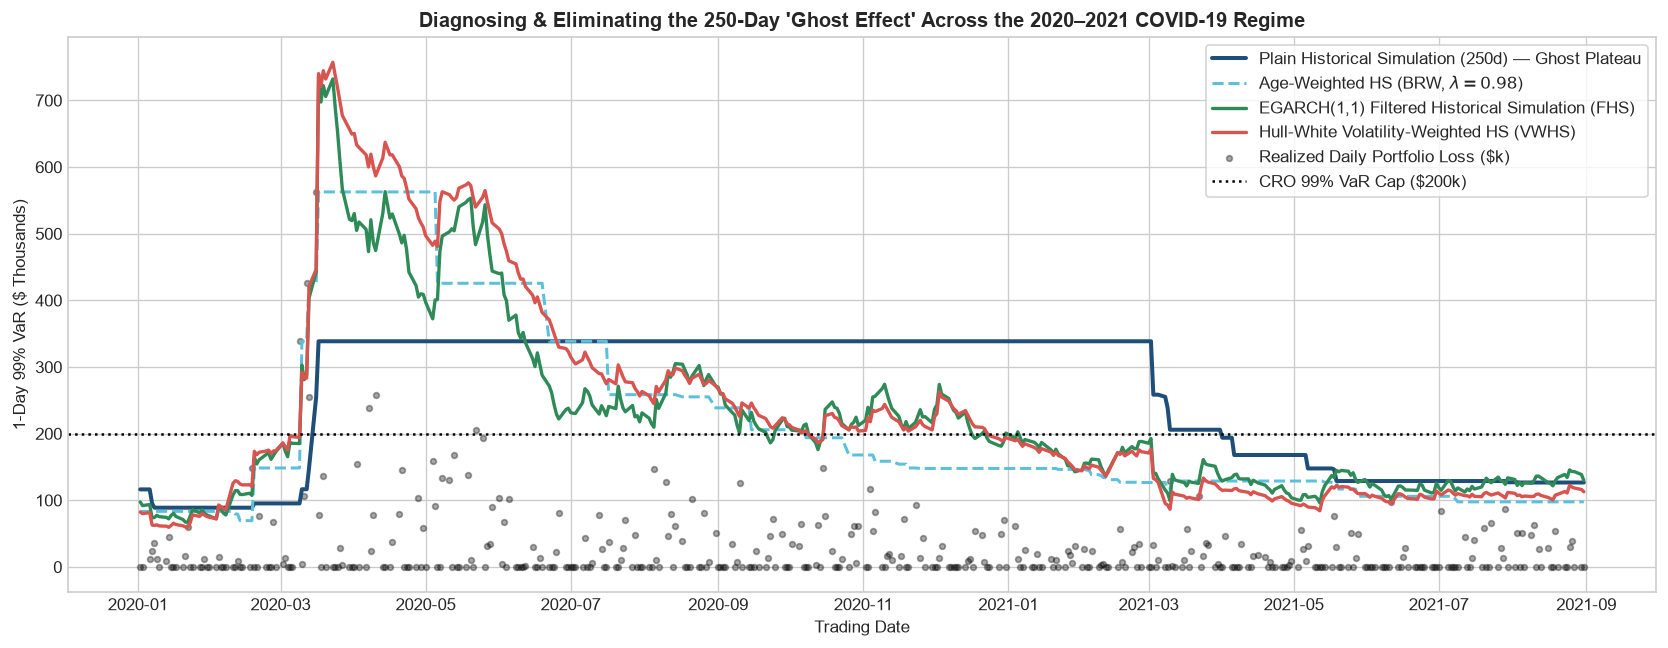

In [3]:
covid_slice = dyn_df.loc["2020-01-01":"2021-08-31"]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(covid_slice.index, covid_slice["Plain_HS_250d_VaR_USD"] / 1e3, color="#1f4e78", lw=2.4, label="Plain Historical Simulation (250d) — Ghost Plateau")
ax.plot(covid_slice.index, covid_slice["Age_Weighted_HS_VaR_USD"] / 1e3, color="#5bc0de", lw=1.8, ls="--", label="Age-Weighted HS (BRW, $\\lambda=0.98$)")
ax.plot(covid_slice.index, covid_slice["EGARCH11_FHS_VaR_USD"] / 1e3, color="#2e8b57", lw=2.0, label="EGARCH(1,1) Filtered Historical Simulation (FHS)")
ax.plot(covid_slice.index, covid_slice["Hull_White_VWHS_VaR_USD"] / 1e3, color="#d9534f", lw=2.0, label="Hull-White Volatility-Weighted HS (VWHS)")
ax.scatter(
    covid_slice.index,
    np.maximum(covid_slice["Realized_Loss_USD"] / 1e3, 0),
    s=12, alpha=0.35, color="black", label="Realized Daily Portfolio Loss ($k)"
)
ax.axhline(cro_var_limit / 1e3, color="black", ls=":", lw=1.5, label="CRO 99% VaR Cap ($200k)")
ax.set_title("Diagnosing & Eliminating the 250-Day 'Ghost Effect' Across the 2020–2021 COVID-19 Regime", fontweight="bold")
ax.set_ylabel("1-Day 99% VaR ($ Thousands)")
ax.set_xlabel("Trading Date")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 3. Regime Comparison: Calm (2017) vs. Crisis (2020 COVID & 2022 Rate-Hike Bear)

In [4]:
exceeds_max_window = dyn_df[dyn_df["Hull_White_VWHS_VaR_USD"] > dyn_df["Max_Window_Loss_USD"]]
print(f"Days where Hull-White 99% VWHS VaR > Max Historical Loss in 250d Window: {len(exceeds_max_window)} trading days")

regime_windows = {
    "2017 Low-Vol Calm": ("2017-01-01", "2017-12-31"),
    "2020 COVID-19 Crash (Q1-Q2)": ("2020-02-01", "2020-05-31"),
    "2021 Post-Crash Recovery (Ghost Window)": ("2021-01-01", "2021-04-30"),
    "2022 Inflation & Rate-Hike Bear": ("2022-01-01", "2022-12-31"),
    "Full Out-of-Sample (2016–2025)": (str(dyn_df.index.min().date()), str(dyn_df.index.max().date())),
}
model_cols = [
    "Plain_HS_250d_VaR_USD",
    "Rolling_Normal_250d_VaR_USD",
    "EWMA_Normal_VaR_USD",
    "GARCH11_Normal_VaR_USD",
    "GARCH11_StudentT_VaR_USD",
    "EGARCH11_FHS_VaR_USD",
    "Age_Weighted_HS_VaR_USD",
    "Hull_White_VWHS_VaR_USD",
]
regime_summary = {label: dyn_df.loc[s_dt:e_dt, model_cols].mean() for label, (s_dt, e_dt) in regime_windows.items()}
pd.DataFrame(regime_summary).T.round(0)

Days where Hull-White 99% VWHS VaR > Max Historical Loss in 250d Window: 669 trading days


,Plain_HS_250d_VaR_USD,Rolling_Normal_250d_VaR_USD,EWMA_Normal_VaR_USD,GARCH11_Normal_VaR_USD,GARCH11_StudentT_VaR_USD,EGARCH11_FHS_VaR_USD,Age_Weighted_HS_VaR_USD,Hull_White_VWHS_VaR_USD
2017 Low-Vol Calm,99304.0,95238.0,80636.0,88334.0,95631.0,90451.0,99654.0,90508.0
2020 COVID-19 Crash (Q1-Q2),251259.0,153118.0,301322.0,296559.0,360612.0,391707.0,383838.0,442395.0
2021 Post-Crash Recovery (Ghost Window),264847.0,202680.0,109576.0,109432.0,130577.0,149152.0,133908.0,137428.0
2022 Inflation & Rate-Hike Bear,218443.0,182584.0,233526.0,225194.0,268447.0,272147.0,244576.0,275752.0
Full Out-of-Sample (2016–2025),166733.0,137736.0,133957.0,133478.0,154645.0,160651.0,153374.0,163438.0


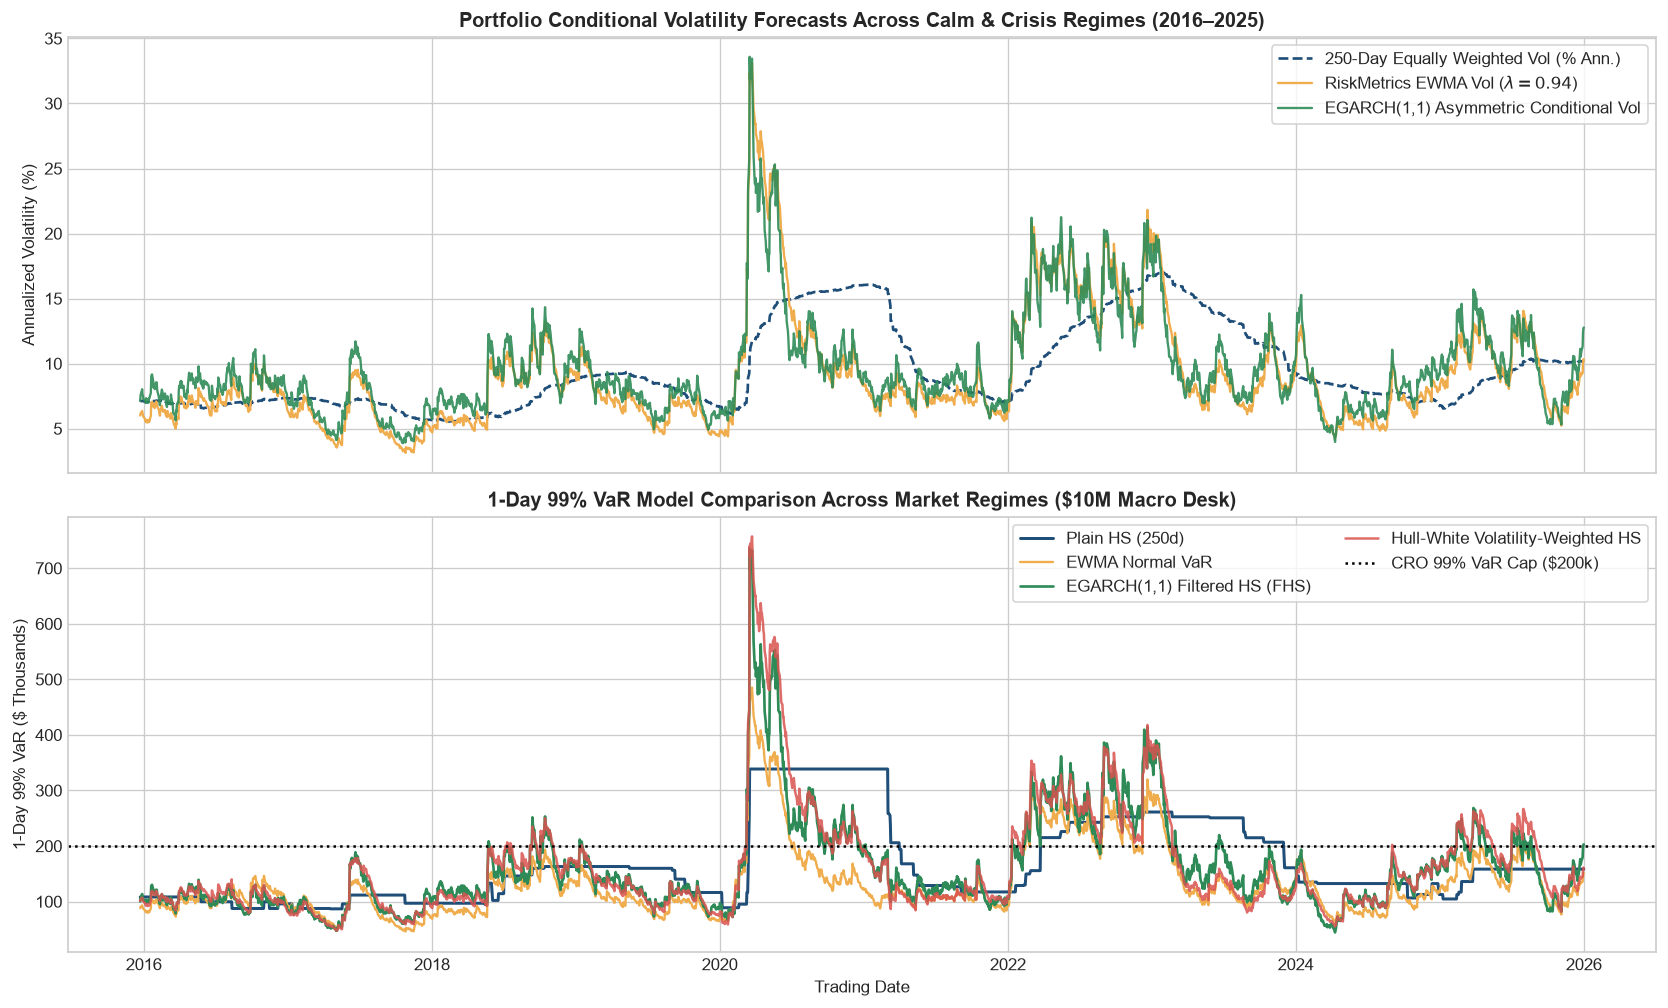

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)

axes[0].plot(dyn_df.index, dyn_df["Rolling_250d_Ann_Vol_pct"], color="#1f4e78", lw=1.6, ls="--", label="250-Day Equally Weighted Vol (% Ann.)")
axes[0].plot(dyn_df.index, dyn_df["EWMA_Ann_Vol_pct"], color="#f0ad4e", lw=1.4, label="RiskMetrics EWMA Vol ($\\lambda=0.94$)")
axes[0].plot(dyn_df.index, dyn_df["EGARCH11_Ann_Vol_pct"], color="#2e8b57", lw=1.4, alpha=0.9, label="EGARCH(1,1) Asymmetric Conditional Vol")
axes[0].set_title("Portfolio Conditional Volatility Forecasts Across Calm & Crisis Regimes (2016–2025)", fontweight="bold")
axes[0].set_ylabel("Annualized Volatility (%)")
axes[0].legend(loc="upper right", frameon=True)

axes[1].plot(dyn_df.index, dyn_df["Plain_HS_250d_VaR_USD"] / 1e3, color="#1f4e78", lw=1.8, label="Plain HS (250d)")
axes[1].plot(dyn_df.index, dyn_df["EWMA_Normal_VaR_USD"] / 1e3, color="#f0ad4e", lw=1.4, label="EWMA Normal VaR")
axes[1].plot(dyn_df.index, dyn_df["EGARCH11_FHS_VaR_USD"] / 1e3, color="#2e8b57", lw=1.6, label="EGARCH(1,1) Filtered HS (FHS)")
axes[1].plot(dyn_df.index, dyn_df["Hull_White_VWHS_VaR_USD"] / 1e3, color="#d9534f", lw=1.5, alpha=0.85, label="Hull-White Volatility-Weighted HS")
axes[1].axhline(cro_var_limit / 1e3, color="black", ls=":", lw=1.5, label="CRO 99% VaR Cap ($200k)")
axes[1].set_title("1-Day 99% VaR Model Comparison Across Market Regimes ($10M Macro Desk)", fontweight="bold")
axes[1].set_ylabel("1-Day 99% VaR ($ Thousands)")
axes[1].set_xlabel("Trading Date")
axes[1].legend(loc="upper right", ncol=2, frameon=True)

plt.tight_layout()
plt.show()